In [5]:
import pandas as pd
import numpy as np

pd.set_option("display.max_columns",None)

In [6]:
train_df=pd.read_csv(r"C:\Users\ayush\Desktop\Credit_card_fraud_detection\data\raw\fraudTrain.csv")
test_df=pd.read_csv(r"C:\Users\ayush\Desktop\Credit_card_fraud_detection\data\raw\fraudTest.csv")

## Phase 1:Verification

In [7]:
print("Training data shape:",train_df.shape)
print("Testing data shape: ",test_df.shape)

Training data shape: (1296675, 23)
Testing data shape:  (555719, 23)


In [8]:
train_df.head()

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,NC,28654,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,WA,99160,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,Malad City,ID,83252,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,Boulder,MT,59632,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,Doe Hill,VA,24433,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [9]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1296675 entries, 0 to 1296674
Data columns (total 23 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   Unnamed: 0             1296675 non-null  int64  
 1   trans_date_trans_time  1296675 non-null  str    
 2   cc_num                 1296675 non-null  int64  
 3   merchant               1296675 non-null  str    
 4   category               1296675 non-null  str    
 5   amt                    1296675 non-null  float64
 6   first                  1296675 non-null  str    
 7   last                   1296675 non-null  str    
 8   gender                 1296675 non-null  str    
 9   street                 1296675 non-null  str    
 10  city                   1296675 non-null  str    
 11  state                  1296675 non-null  str    
 12  zip                    1296675 non-null  int64  
 13  lat                    1296675 non-null  float64
 14  long                   129667

In [10]:
train_df.describe()

,Unnamed: 0,cc_num,amt,zip,lat,long,city_pop,unix_time,merch_lat,merch_long,is_fraud
count,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06
mean,6.483370e+05,4.171920e+17,7.035104e+01,4.880067e+04,3.853762e+01,-9.022634e+01,8.882444e+04,1.349244e+09,3.853734e+01,-9.022646e+01,5.788652e-03
std,3.743180e+05,1.308806e+18,1.603160e+02,2.689322e+04,5.075808e+00,1.375908e+01,3.019564e+05,1.284128e+07,5.109788e+00,1.377109e+01,7.586269e-02
min,0.000000e+00,6.041621e+10,1.000000e+00,1.257000e+03,2.002710e+01,-1.656723e+02,2.300000e+01,1.325376e+09,1.902779e+01,-1.666712e+02,0.000000e+00
25%,3.241685e+05,1.800429e+14,9.650000e+00,2.623700e+04,3.462050e+01,-9.679800e+01,7.430000e+02,1.338751e+09,3.473357e+01,-9.689728e+01,0.000000e+00
50%,6.483370e+05,3.521417e+15,4.752000e+01,4.817400e+04,3.935430e+01,-8.747690e+01,2.456000e+03,1.349250e+09,3.936568e+01,-8.743839e+01,0.000000e+00
75%,9.725055e+05,4.642255e+15,8.314000e+01,7.204200e+04,4.194040e+01,-8.015800e+01,2.032800e+04,1.359385e+09,4.195716e+01,-8.023680e+01,0.000000e+00
max,1.296674e+06,4.992346e+18,2.894890e+04,9.978300e+04,6.669330e+01,-6.795030e+01,2.906700e+06,1.371817e+09,6.751027e+01,-6.695090e+01,1.000000e+00


In [11]:
train_df.describe(include='object')

C:\Users\ayush\AppData\Local\Temp\ipykernel_21852\1490267509.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  train_df.describe(include='object')


,trans_date_trans_time,merchant,category,first,last,gender,street,city,state,job,dob,trans_num
count,1296675,1296675,1296675,1296675,1296675,1296675,1296675,1296675,1296675,1296675,1296675,1296675
unique,1274791,693,14,352,481,2,983,894,51,494,968,1296675
top,2019-04-22 16:02:01,fraud_Kilback LLC,gas_transport,Christopher,Smith,F,864 Reynolds Plains,Birmingham,TX,Film/video editor,1977-03-23,0b242abb623afc578575680df30655b9
freq,4,4403,131659,26669,28794,709863,3123,5617,94876,9779,5636,1


In [12]:
train_df.columns.tolist()

['Unnamed: 0',
 'trans_date_trans_time',
 'cc_num',
 'merchant',
 'category',
 'amt',
 'first',
 'last',
 'gender',
 'street',
 'city',
 'state',
 'zip',
 'lat',
 'long',
 'city_pop',
 'job',
 'dob',
 'trans_num',
 'unix_time',
 'merch_lat',
 'merch_long',
 'is_fraud']

In [13]:
print(train_df["is_fraud"].value_counts(normalize=True)*100)

is_fraud
0    99.421135
1     0.578865
Name: proportion, dtype: float64


In [14]:
train_df.isnull().sum()

Unnamed: 0               0
trans_date_trans_time    0
cc_num                   0
merchant                 0
category                 0
amt                      0
first                    0
last                     0
gender                   0
street                   0
city                     0
state                    0
zip                      0
lat                      0
long                     0
city_pop                 0
job                      0
dob                      0
trans_num                0
unix_time                0
merch_lat                0
merch_long               0
is_fraud                 0
dtype: int64

In [15]:
print("Duplicate rows",train_df.duplicated().sum())

Duplicate rows 0


## Phase 2: EDA

In [16]:
print("Class counts: ",train_df["is_fraud"].value_counts())
print("-"*50)
print("Class count percentage: ",train_df['is_fraud'].value_counts(normalize=True)*100)



Class counts:  is_fraud
0    1289169
1       7506
Name: count, dtype: int64
--------------------------------------------------
Class count percentage:  is_fraud
0    99.421135
1     0.578865
Name: proportion, dtype: float64


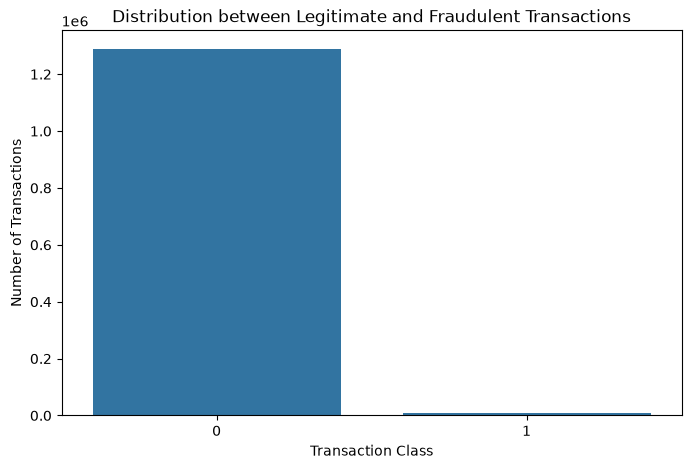

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.countplot(data=train_df,x='is_fraud')
plt.title("Distribution between Legitimate and Fraudulent Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.show()

##### The dataset is highly imbalanced, with legitimate transactions significantly outnumbering fraudulent transactions. Therefore, accuracy alone will not be a reliable evaluation metric. The project will focus on precision, recall, F1-score, PR-AUC, and ROC-AUC. Techniques such as class weighting and resampling will be evaluated during the modeling phase.

In [18]:
train_df['amt'].describe()

count    1.296675e+06
mean     7.035104e+01
std      1.603160e+02
min      1.000000e+00
25%      9.650000e+00
50%      4.752000e+01
75%      8.314000e+01
max      2.894890e+04
Name: amt, dtype: float64

In [19]:
train_df.groupby('is_fraud')["amt"].describe()

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,1289169.0,67.667110,154.007971,1.00,9.6100,47.280,82.540,28948.90
1,7506.0,531.320092,390.560070,1.06,245.6625,396.505,900.875,1376.04


In [20]:
train_df["log_amt"]=np.log1p(train_df["amt"])

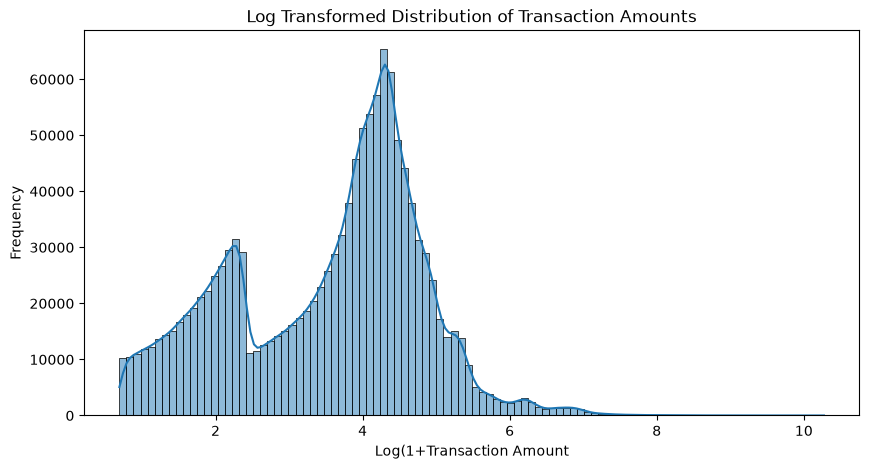

In [21]:
plt.figure(figsize=(10,5))
sns.histplot(data=train_df,x="log_amt",bins=100,kde=True)
plt.title("Log Transformed Distribution of Transaction Amounts")
plt.xlabel("Log(1+Transaction Amount")
plt.ylabel("Frequency")
plt.show()

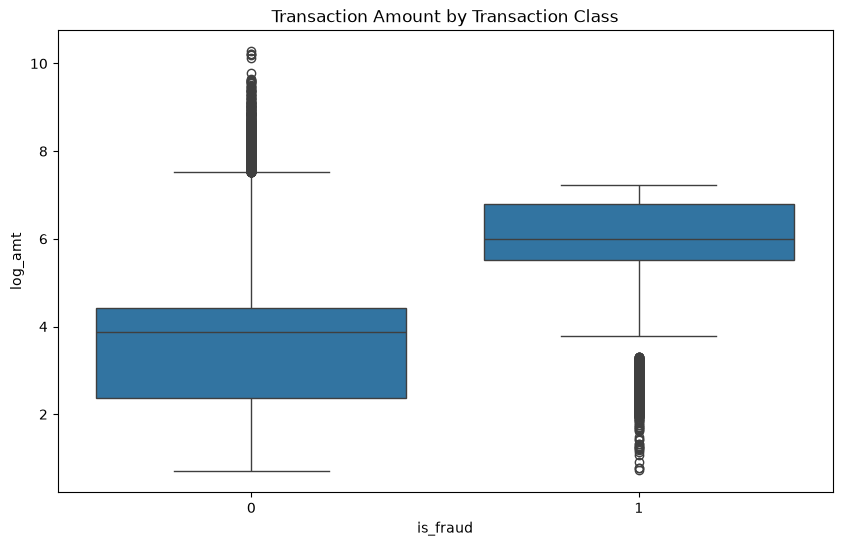

In [22]:
plt.figure(figsize=(10,6))

sns.boxplot(data=train_df,x='is_fraud',y="log_amt")
plt.title("Transaction Amount by Transaction Class")
plt.show()

In [23]:
amt_comparison=train_df.groupby("is_fraud")["amt"].agg(["count","mean","median","min","max"])
amt_comparison

,count,mean,median,min,max
is_fraud,,,,,
0,1289169,67.667110,47.280,1.00,28948.90
1,7506,531.320092,396.505,1.06,1376.04


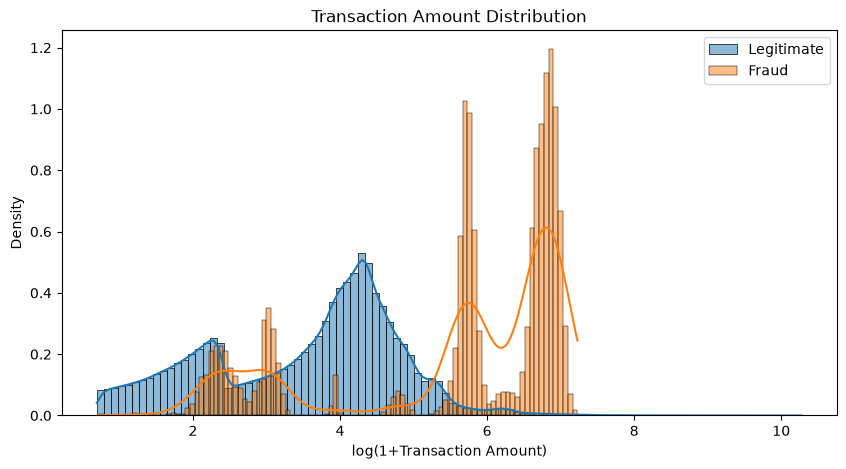

In [24]:
plt.figure(figsize=(10,5))

sns.histplot(data=train_df[train_df["is_fraud"]==0],x="log_amt",bins=100,stat="density",kde=True,label="Legitimate",alpha=0.5)

sns.histplot(data=train_df[train_df["is_fraud"]==1],x="log_amt",bins=100,stat="density",kde=True,label="Fraud",alpha=0.5)

plt.title("Transaction Amount Distribution")
plt.xlabel("log(1+Transaction Amount)")
plt.ylabel("Density")
plt.legend()
plt.show()

In [25]:
train_df.drop(columns="log_amt",inplace=True)

##### Transaction Amount Analysis: Transaction amounts show a skewed distribution, with a large proportion of transactions concentrated at lower values and relatively fewer high-value transactions. Comparing fraud rates across transaction amount ranges helps determine whether certain spending ranges have a higher fraud prevalence. Transaction amount is expected to be a useful feature but should be combined with temporal, geographic, and behavioral features for effective fraud detection.

In [26]:
train_df["category"].unique().tolist()

['misc_net',
 'grocery_pos',
 'entertainment',
 'gas_transport',
 'misc_pos',
 'grocery_net',
 'shopping_net',
 'shopping_pos',
 'food_dining',
 'personal_care',
 'health_fitness',
 'travel',
 'kids_pets',
 'home']

In [27]:
print("Number of categories: ",train_df["category"].nunique())

Number of categories:  14


In [28]:
train_df["category"].value_counts()

category
gas_transport     131659
grocery_pos       123638
home              123115
shopping_pos      116672
kids_pets         113035
shopping_net       97543
entertainment      94014
food_dining        91461
personal_care      90758
health_fitness     85879
misc_pos           79655
misc_net           63287
grocery_net        45452
travel             40507
Name: count, dtype: int64

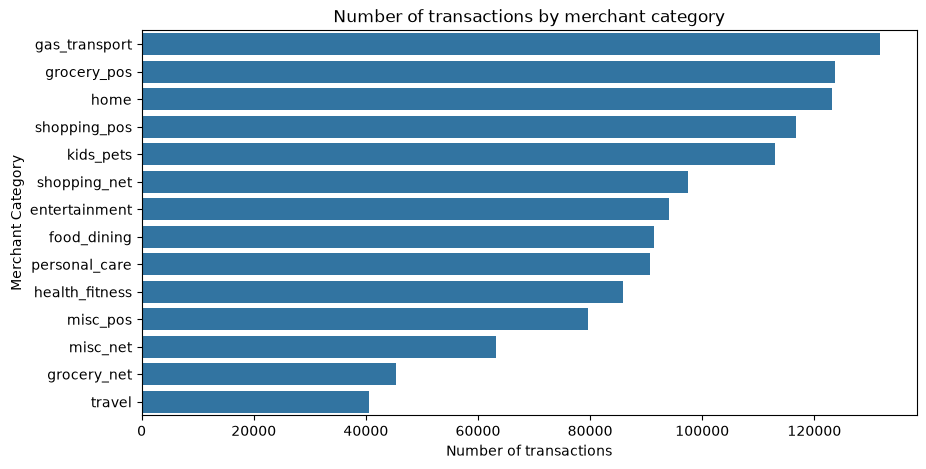

In [29]:
plt.figure(figsize=(10,5))
sns.countplot(data=train_df,y="category",order=train_df["category"].value_counts().index)
plt.title("Number of transactions by merchant category")
plt.xlabel("Number of transactions")
plt.ylabel("Merchant Category")
plt.show()

In [30]:
fraud_category=train_df[train_df["is_fraud"]==1]["category"].value_counts()
fraud_category

category
grocery_pos       1743
shopping_net      1713
misc_net           915
shopping_pos       843
gas_transport      618
misc_pos           250
kids_pets          239
entertainment      233
personal_care      220
home               198
food_dining        151
grocery_net        134
health_fitness     133
travel             116
Name: count, dtype: int64

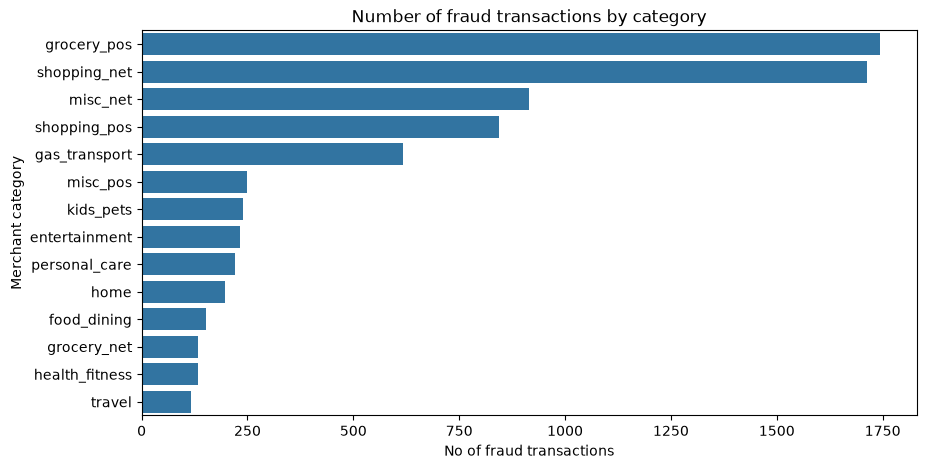

In [ ]:
plt.figure(figsize=(10,5))
sns.barplot(x=fraud_category.values,y=fraud_category.index)
plt.title("Number of fraud transactions by category")
plt.xlabel("No of fraud transactions")
plt.ylabel("Merchant category")
plt.show()

Fraud rate more meaningful than fraud count

In [36]:
category_analysis=(train_df.groupby("category").agg(total_transactions=("is_fraud","count"),fraud_transactions=("is_fraud", "sum"),
        fraud_rate=("is_fraud", "mean")))
category_analysis["fraud_rate"] *= 100
category_analysis = category_analysis.sort_values(
    "fraud_rate",
    ascending=False
)
category_analysis.round(3)

,total_transactions,fraud_transactions,fraud_rate
category,,,
shopping_net,97543,1713,1.756
misc_net,63287,915,1.446
grocery_pos,123638,1743,1.410
shopping_pos,116672,843,0.723
gas_transport,131659,618,0.469
misc_pos,79655,250,0.314
grocery_net,45452,134,0.295
travel,40507,116,0.286
entertainment,94014,233,0.248


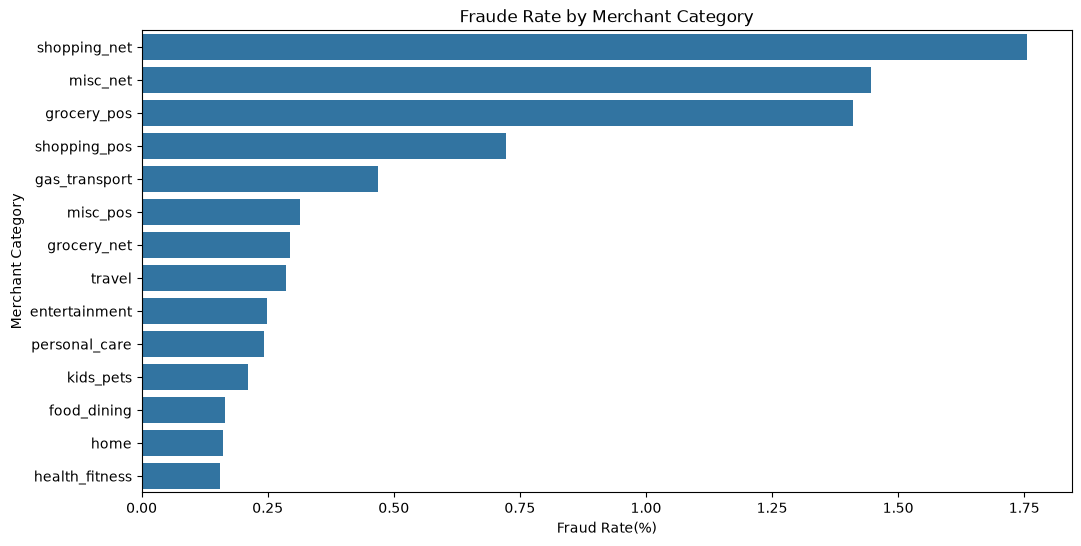

In [37]:
plt.figure(figsize=(12,6))
sns.barplot(data=category_analysis.reset_index(),x="fraud_rate",y="category")
plt.title("Fraude Rate by Merchant Category")
plt.xlabel("Fraud Rate(%)")
plt.ylabel("Merchant Category")
plt.show()

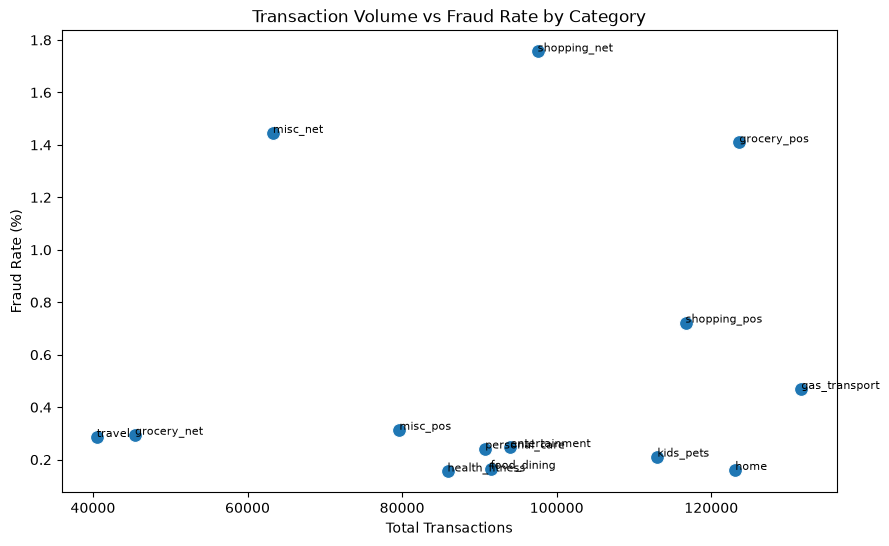

In [38]:
category_plot = category_analysis.reset_index()
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=category_plot,
    x="total_transactions",
    y="fraud_rate",
    s=100
)
for _, row in category_plot.iterrows():
    plt.text(
        row["total_transactions"],
        row["fraud_rate"],
        row["category"],
        fontsize=8
    )

plt.title("Transaction Volume vs Fraud Rate by Category")
plt.xlabel("Total Transactions")
plt.ylabel("Fraud Rate (%)")

plt.show()

Merchant Category Analysis: Transaction categories show different transaction volumes and fraud rates. Fraud counts alone are insufficient for identifying risky categories because categories with higher transaction volumes naturally tend to have more fraud cases. Therefore, fraud rate was calculated to compare the relative fraud risk across merchant categories. Merchant category will be retained as a potentially useful feature for the machine learning models

In [ ]:
train_df["trans_date_trans_time"] = pd.to_datetime(train_df["trans_date_trans_time"])

In [45]:
train_df["transaction_hour"] = (train_df["trans_date_trans_time"].dt.hour)

In [46]:
train_df["transaction_hour"].value_counts().sort_index()

transaction_hour
0     42502
1     42869
2     42656
3     42769
4     41863
5     42171
6     42300
7     42203
8     42505
9     42185
10    42271
11    42082
12    65257
13    65314
14    64885
15    65391
16    65726
17    65450
18    66051
19    65508
20    65098
21    65533
22    66982
23    67104
Name: count, dtype: int64

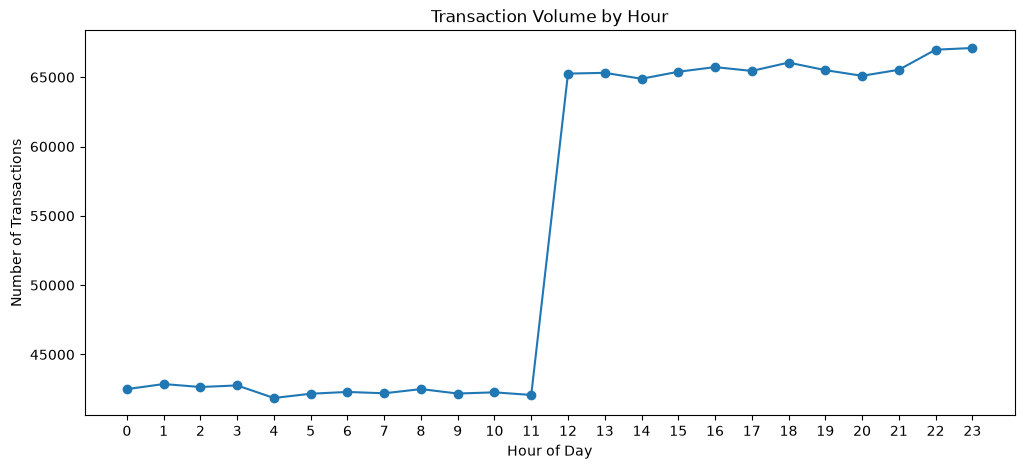

In [47]:
hourly_transactions = (
    train_df["transaction_hour"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(12, 5))

plt.plot(
    hourly_transactions.index,
    hourly_transactions.values,
    marker="o"
)

plt.title("Transaction Volume by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Transactions")
plt.xticks(range(24))

plt.show()

In [48]:
fraud_by_hour = (train_df[train_df["is_fraud"] == 1]
    .groupby("transaction_hour")
    .size()
)

fraud_by_hour = fraud_by_hour.reindex(range(24),fill_value=0)

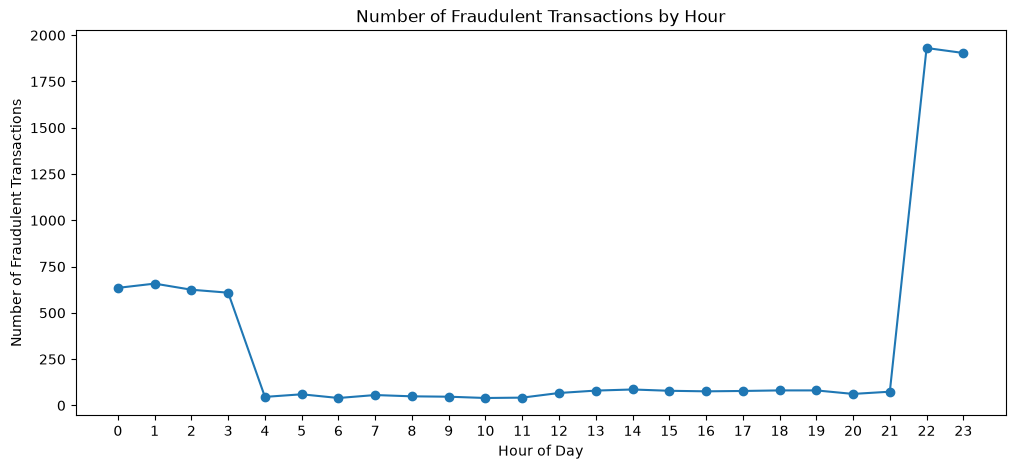

In [49]:
plt.figure(figsize=(12, 5))

plt.plot(
    fraud_by_hour.index,
    fraud_by_hour.values,
    marker="o"
)

plt.title("Number of Fraudulent Transactions by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Fraudulent Transactions")
plt.xticks(range(24))

plt.show()

In [50]:
fraud_rate_by_hour = (
    train_df
    .groupby("transaction_hour")["is_fraud"]
    .mean()
    * 100
)

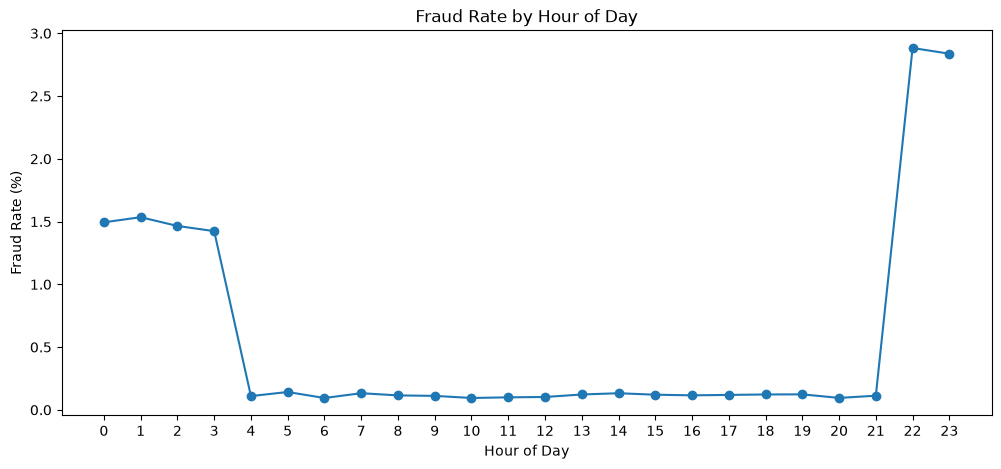

In [51]:
plt.figure(figsize=(12, 5))

plt.plot(
    fraud_rate_by_hour.index,
    fraud_rate_by_hour.values,
    marker="o"
)

plt.title("Fraud Rate by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Fraud Rate (%)")
plt.xticks(range(24))

plt.show()

In [53]:
train_df["day_of_week"] = (
    train_df["trans_date_trans_time"].dt.day_name()
)
train_df["day_of_week"].value_counts()
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

In [54]:
fraud_rate_by_day = (
    train_df
    .groupby("day_of_week")["is_fraud"]
    .mean()
    .reindex(day_order)
    * 100
)

fraud_rate_by_day

day_of_week
Monday       0.464838
Tuesday      0.583547
Wednesday    0.655360
Thursday     0.684387
Friday       0.708600
Saturday     0.610578
Sunday       0.485276
Name: is_fraud, dtype: float64

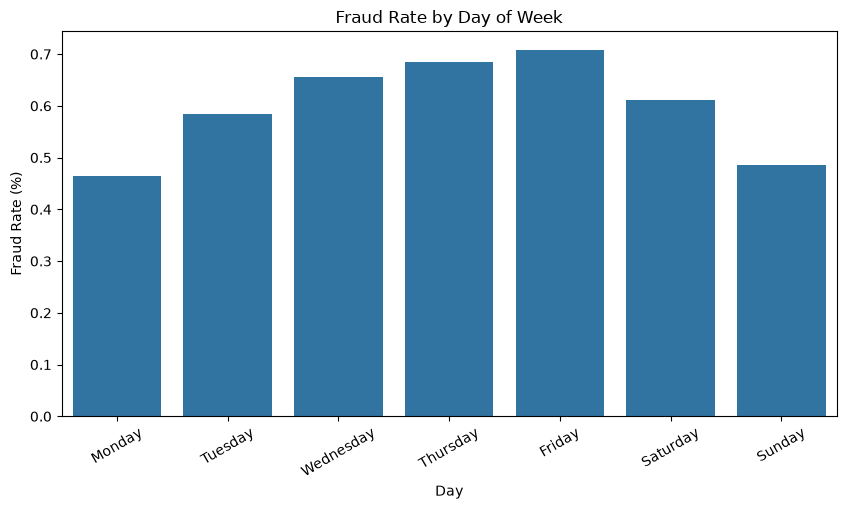

In [55]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=fraud_rate_by_day.index,
    y=fraud_rate_by_day.values
)

plt.title("Fraud Rate by Day of Week")
plt.xlabel("Day")
plt.ylabel("Fraud Rate (%)")

plt.xticks(rotation=30)

plt.show()

In [56]:
train_df["is_weekend"] = (
    train_df["trans_date_trans_time"].dt.dayofweek >= 5
)
weekend_fraud_rate = (
    train_df
    .groupby("is_weekend")["is_fraud"]
    .mean()
    * 100
)

weekend_fraud_rate

is_weekend
False    0.599073
True     0.541042
Name: is_fraud, dtype: float64

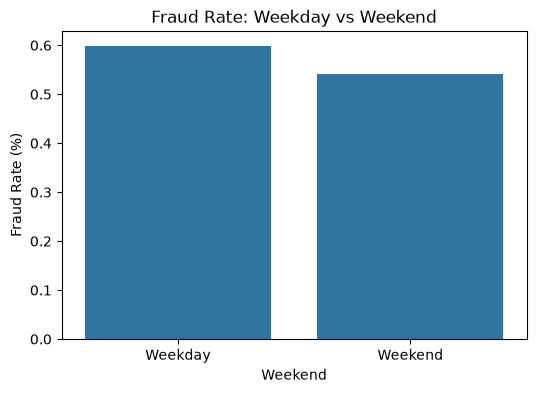

In [57]:
plt.figure(figsize=(6, 4))

sns.barplot(
    x=weekend_fraud_rate.index,
    y=weekend_fraud_rate.values
)

plt.title("Fraud Rate: Weekday vs Weekend")
plt.xlabel("Weekend")
plt.ylabel("Fraud Rate (%)")

plt.xticks(
    [0, 1],
    ["Weekday", "Weekend"]
)

plt.show()

In [58]:
time_analysis = pd.DataFrame({
    "Fraud Rate by Hour": fraud_rate_by_hour
})

time_analysis.head()

,Fraud Rate by Hour
transaction_hour,
0,1.494047
1,1.534909
2,1.465210
3,1.423929
4,0.109882


In [60]:
fraud_rate_by_hour.sort_values(
    ascending=False
).head(5)

transaction_hour
22    2.882864
23    2.837387
1     1.534909
0     1.494047
2     1.465210
Name: is_fraud, dtype: float64

In [61]:
train_df["transaction_month"] = (
    train_df["trans_date_trans_time"].dt.month
)
fraud_rate_by_month = (
    train_df
    .groupby("transaction_month")["is_fraud"]
    .mean()
    * 100
)

fraud_rate_by_month

transaction_month
1     0.810679
2     0.873465
3     0.652345
4     0.502334
5     0.636596
6     0.478406
7     0.382235
8     0.437276
9     0.591632
10    0.660287
11    0.550972
12    0.419680
Name: is_fraud, dtype: float64

Time-Based Analysis: Transaction activity and fraud rates vary across different hours and days. Time-derived features such as transaction hour, day of week, weekend indicator, and potentially month may provide useful contextual information for fraud detection. These features will be evaluated during feature engineering and model development.

In [62]:
train_df.drop(
    columns=[
        "transaction_hour",
        "day_of_week",
        "is_weekend",
        "transaction_month"
    ],
    inplace=True
)